# Table A1 — Comparison with LMC statistical complexity

This notebook compares LMC complexity with the translation and
reflection components of statistical asymmetry for binary sequences
of length 100.

LMC complexity is the product of Shannon entropy (using natural
logarithms) and the squared distance from the uniform distribution.
The probabilities come from all 100 overlapping bigrams, including
the pair formed by the last and first symbols.

The homogeneous, alternating, and half-filled sequences are
deterministic. Each stochastic row averages 20,000 independently
generated sequences using NumPy seed `55`. The defect model flips
five distinct positions chosen uniformly from the alternating sequence.
The table displays the recomputed values to four decimal places.
The last two rows are Monte Carlo means and can differ slightly
from the values printed in the paper.

In [1]:
import matplotlib.pyplot as plt
import numpy as np


def statistical_asymmetry(distances, sequence_length):
    _, counts = np.unique(distances, return_counts=True)
    probabilities = counts / len(distances)
    entropy = -np.sum(probabilities * np.log(probabilities))
    return (entropy / np.log(len(distances))) * (
        max(distances) / sequence_length
    )


def asymmetry_components(sequence):
    state = np.asarray(sequence)
    length = len(state)
    translation_distances = [
        np.count_nonzero(state != np.roll(state, shift))
        for shift in range(length // 2 + 1)
    ]
    reflection_distances = [0, np.count_nonzero(state != state[::-1])]
    return (
        statistical_asymmetry(translation_distances, length),
        statistical_asymmetry(reflection_distances, length),
    )


def lmc_complexity(sequence):
    bigrams = 2 * sequence + np.roll(sequence, -1)
    probabilities = np.bincount(bigrams, minlength=4) / sequence.size
    positive = probabilities[probabilities > 0]
    entropy = -np.sum(positive * np.log(positive))
    disequilibrium = np.sum((probabilities - 0.25) ** 2)
    return entropy * disequilibrium + 0.0


def measures(sequence):
    return (lmc_complexity(sequence), *asymmetry_components(sequence))


length = 100
runs = 20_000
rng = np.random.default_rng(55)

alternating = np.tile([0, 1], length // 2)
fixed_sequences = {
    "Homogeneous": np.zeros(length, dtype=int),
    "Alternating": alternating,
    "Half-filled": np.repeat([1, 0], length // 2),
}

results = {name: measures(state) for name, state in fixed_sequences.items()}
defect_scores = np.empty((runs, 3))
random_scores = np.empty((runs, 3))

for run in range(runs):
    defective = alternating.copy()
    positions = rng.choice(length, size=5, replace=False)
    defective[positions] ^= 1
    defect_scores[run] = measures(defective)
    random_scores[run] = measures(rng.integers(0, 2, size=length))

samples = {
    "Alternating with defects": defect_scores,
    "Random": random_scores,
}
results.update({name: scores.mean(axis=0) for name, scores in samples.items()})

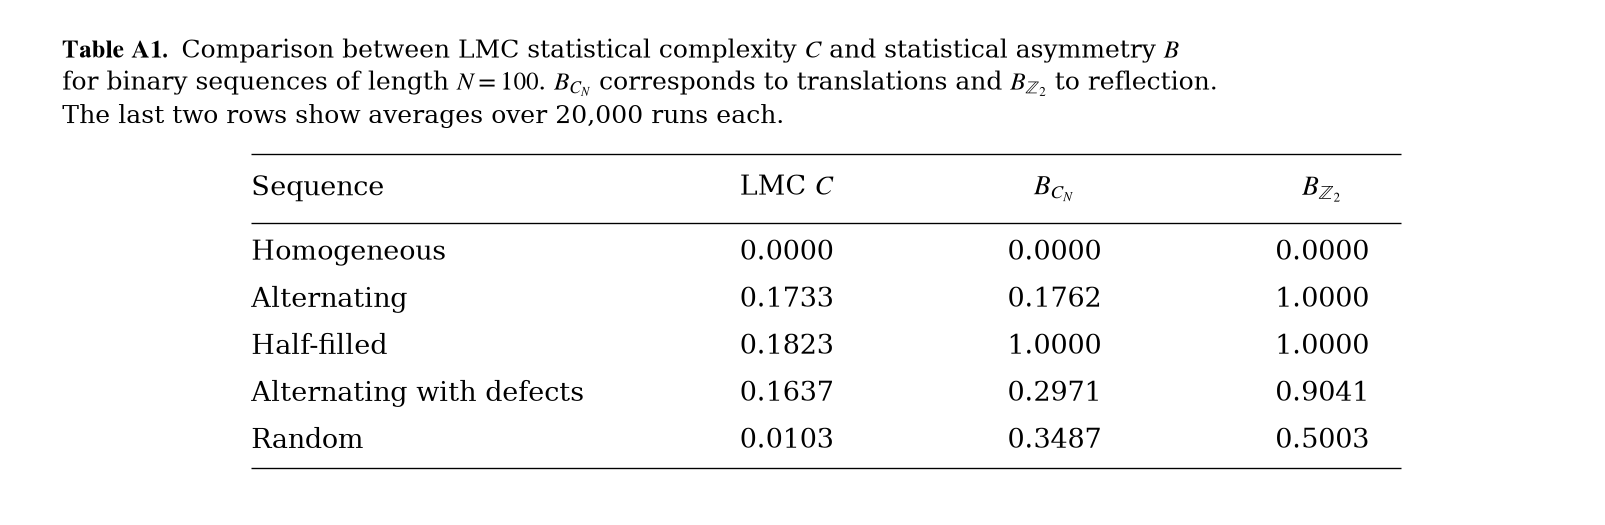

In [2]:
with plt.rc_context({
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "text.color": "black",
}):
    fig, ax = plt.subplots(figsize=(10.5, 3.3), dpi=150)
    fig.patch.set_facecolor("white")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    ax.text(
        0.03, 0.96,
        r"$\mathbf{Table\ A1.}$ Comparison between LMC statistical "
        r"complexity $C$ and statistical asymmetry $B$"
        "\n"
        r"for binary sequences of length $N = 100$. "
        r"$B_{C_N}$ corresponds to translations and $B_{\mathbb{Z}_2}$ to reflection."
        "\n"
        "The last two rows show averages over 20,000 runs each.",
        va="top", fontsize=12, linespacing=1.3,
    )

    sequence_x = 0.15
    score_x = (0.49, 0.66, 0.83)
    ax.hlines([0.72, 0.58, 0.085], sequence_x, 0.88,
              color="black", linewidth=0.65)

    ax.text(sequence_x, 0.65, "Sequence", va="center", fontsize=13)
    for x, heading in zip(
        score_x, (r"LMC $C$", r"$B_{C_N}$", r"$B_{\mathbb{Z}_2}$")
    ):
        ax.text(x, 0.65, heading, ha="center", va="center", fontsize=13)

    for row, (name, scores) in enumerate(results.items()):
        y = 0.52 - 0.095 * row
        ax.text(sequence_x, y, name, va="center", fontsize=13)
        for x, score in zip(score_x, scores):
            ax.text(
                x, y, f"{float(score) + 0.0:.4f}",
                ha="center", va="center", fontsize=13,
            )

    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    plt.show()